# CIFAR-10 CNN for object classification on the e-puck (Webots)

This notebook trains a convolutional neural network (CNN) on CIFAR-10. It also:

1. compares the SGD and Adam optimisers under identical conditions,
2. evaluates the final model on the held-out test set (accuracy, confusion matrix, most-confused classes),
3. classifies images of our own,
4. prepares the model for the robot: TensorFlow Lite conversion, int8 quantisation and inference-time measurement.

The saved model (`final_model.keras`) is loaded by the Webots controller `opencv.py`.

## About the dataset

CIFAR-10 is a labelled subset of the *80 Million Tiny Images* collection. It contains **60,000 colour images of 32 × 32 pixels in 10 classes** (6,000 per class): **50,000 for training** and **10,000 for testing**.

Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.

To keep the test set unseen until the final evaluation, 5,000 training images are held out as a **validation set** for monitoring training and early stopping.


## Running this notebook in Google Colab

1. Go to [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. **Runtime → Change runtime type → T4 GPU**. Training then takes about 2–3 minutes instead of about 30 on a laptop CPU.
3. **Runtime → Run all**. Before the *own images* section, a file picker asks for your photos (for example `sample_deer.png`, `webots_horse.png`, `webots_car.png` from `notebooks/my_images/`).
4. At the end, the trained models download automatically. Copy `final_model.keras` into the Webots controller folder `controllers/opencv/`.

The cells marked *Colab only* do nothing when the notebook runs in local Jupyter.


In [ ]:

# Colab only: report whether a GPU is available (training works without one, just slower)
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    import tensorflow as tf
    gpus = tf.config.list_physical_devices('GPU')
    print("GPU:", gpus[0].name if gpus else "none - use Runtime > Change runtime type > T4 GPU")


In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow
print("TensorFlow", tf.__version__)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

TensorFlow 2.19.1


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Labels come as shape (N, 1); flatten them to (N,)
train_labels = train_labels.flatten()
test_labels = test_labels.flatten()

# Normalise pixel values to [0, 1]
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

# Hold out the last 5,000 training images for validation (the test set stays unseen)
x_train, y_train = train_images[:45000], train_labels[:45000]
x_val, y_val = train_images[45000:], train_labels[45000:]

print(f"train {x_train.shape}, validation {x_val.shape}, test {test_images.shape}")

        0/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

     8192/170498071 ━━━━━━━━━━━━━━━━━━━━ 40:01 14us/step

    16384/170498071 ━━━━━━━━━━━━━━━━━━━━ 38:12 13us/step

    24576/170498071 ━━━━━━━━━━━━━━━━━━━━ 35:33 13us/step

    32768/170498071 ━━━━━━━━━━━━━━━━━━━━ 36:15 13us/step

    40960/170498071 ━━━━━━━━━━━━━━━━━━━━ 35:33 13us/step

... (17,975 outputs left out)

170483712/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 15us/step

170491904/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 15us/step

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2592s 15us/step


train (45000, 32, 32, 3), validation (5000, 32, 32, 3), test (10000, 32, 32, 3)


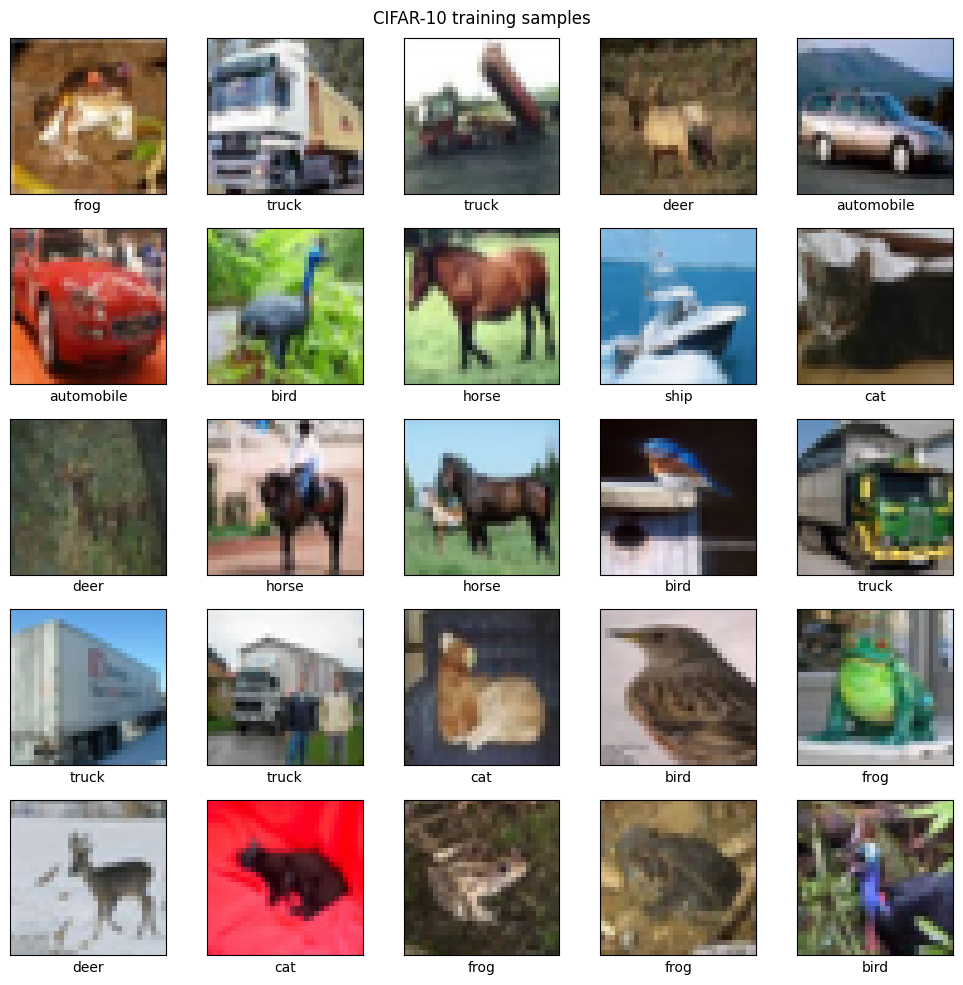

In [3]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i]])
plt.suptitle('CIFAR-10 training samples')
plt.tight_layout()
plt.show()

## Input pipeline and data augmentation

Random horizontal flips and small shifts (up to 10 %) are applied **to the training images only**. The augmentation runs inside the `tf.data` pipeline rather than in the model, so the saved model contains only the classifier and the robot controller can use it directly.

In [4]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1, fill_mode='reflect'),
], name='augmentation')

def make_dataset(x, y, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(10000, seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda img, lbl: (augment(img, training=True), lbl),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val, training=False)
test_ds = make_dataset(test_images, test_labels, training=False)

## Creating the CNN model

Two convolutional blocks, each with two 3 × 3 convolutions, batch normalisation, ReLU and 2 × 2 max pooling. A dense classifier with dropout follows. The last layer uses **softmax**, so the model outputs class probabilities directly; these are used as the confidence score.

In [5]:
def conv_bn_relu(filters):
    return [layers.Conv2D(filters, (3, 3), padding='same', use_bias=False),
            layers.BatchNormalization(),
            layers.Activation('relu')]

def build_model():
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        *conv_bn_relu(32),
        *conv_bn_relu(32),
        layers.MaxPooling2D((2, 2)),
        *conv_bn_relu(64),
        *conv_bn_relu(64),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10, activation='softmax'),
    ], name='cifar10_cnn')

build_model().summary()

Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,850 (2.26 MB)

 Trainable params: 591,466 (2.26 MB)

 Non-trainable params: 384 (1.50 KB)

## Training: SGD vs Adam

Each optimiser trains a **freshly initialised** model with the same data, epochs and seed, so the comparison is fair. Early stopping monitors the validation accuracy and restores the best weights.

In [6]:
EPOCHS = 20

def train(optimizer, label):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model()
    model.compile(optimizer=optimizer,
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=['accuracy'])
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=5, restore_best_weights=True)
    start = time.time()
    history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds,
                        callbacks=[early_stop], verbose=2)
    print(f"{label}: trained in {(time.time() - start) / 60:.1f} min")
    return model, history

sgd_model, sgd_history = train(tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), 'SGD')

Epoch 1/20


704/704 - 143s - 202ms/step - accuracy: 0.2316 - loss: 1.9870 - val_accuracy: 0.3556 - val_loss: 1.7232


Epoch 2/20


704/704 - 135s - 191ms/step - accuracy: 0.3183 - loss: 1.7885 - val_accuracy: 0.4000 - val_loss: 1.6777


Epoch 3/20


704/704 - 151s - 214ms/step - accuracy: 0.4125 - loss: 1.5738 - val_accuracy: 0.5148 - val_loss: 1.3397


... (31 outputs left out)

704/704 - 105s - 148ms/step - accuracy: 0.7630 - loss: 0.6966 - val_accuracy: 0.7288 - val_loss: 0.8173


Epoch 20/20


704/704 - 102s - 145ms/step - accuracy: 0.7696 - loss: 0.6801 - val_accuracy: 0.7778 - val_loss: 0.6690


SGD: trained in 40.7 min


In [7]:
adam_model, adam_history = train(tf.keras.optimizers.Adam(learning_rate=1e-3), 'Adam')

Epoch 1/20


704/704 - 108s - 154ms/step - accuracy: 0.1873 - loss: 2.1293 - val_accuracy: 0.2132 - val_loss: 2.0000


Epoch 2/20


704/704 - 114s - 161ms/step - accuracy: 0.2275 - loss: 1.9617 - val_accuracy: 0.2948 - val_loss: 1.8358


Epoch 3/20


704/704 - 112s - 160ms/step - accuracy: 0.2407 - loss: 1.9075 - val_accuracy: 0.3060 - val_loss: 2.0140


... (13 outputs left out)

704/704 - 116s - 165ms/step - accuracy: 0.2948 - loss: 1.7364 - val_accuracy: 0.3306 - val_loss: 1.6289


Epoch 11/20


704/704 - 145s - 206ms/step - accuracy: 0.3018 - loss: 1.7234 - val_accuracy: 0.3596 - val_loss: 1.6150


Adam: trained in 22.6 min


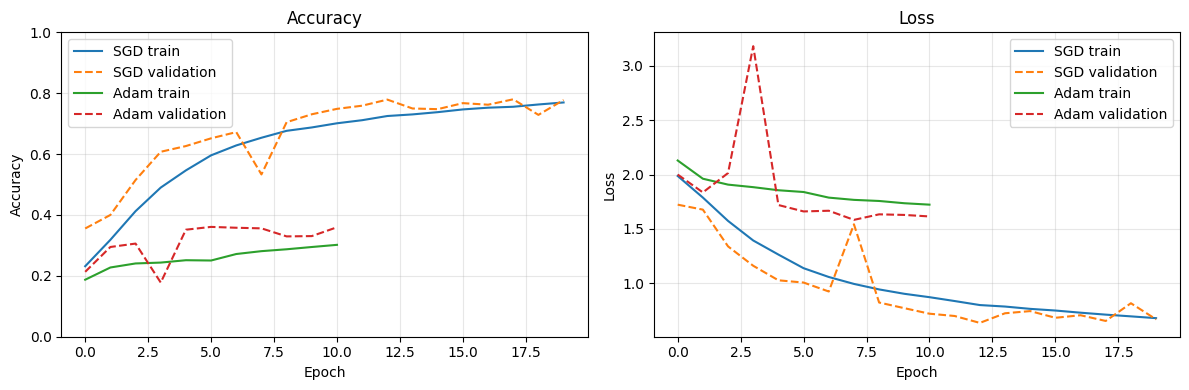

SGD  test accuracy: 77.25%  (test loss 0.681)


Adam test accuracy: 35.49%  (test loss 1.659)


In [8]:
def plot_history(histories):
    fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4))
    for label, h in histories.items():
        ax_acc.plot(h.history['accuracy'], label=f'{label} train')
        ax_acc.plot(h.history['val_accuracy'], '--', label=f'{label} validation')
        ax_loss.plot(h.history['loss'], label=f'{label} train')
        ax_loss.plot(h.history['val_loss'], '--', label=f'{label} validation')
    ax_acc.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1), title='Accuracy')
    ax_loss.set(xlabel='Epoch', ylabel='Loss', title='Loss')
    for ax in (ax_acc, ax_loss):
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history({'SGD': sgd_history, 'Adam': adam_history})

results = {}
for label, m in [('SGD', sgd_model), ('Adam', adam_model)]:
    loss, acc = m.evaluate(test_ds, verbose=0)
    results[label] = acc
    print(f"{label:4s} test accuracy: {acc:.2%}  (test loss {loss:.3f})")


**Why Adam did worse here.** With this model, Adam stalled at about 30 % training accuracy, while SGD with momentum kept improving to 77 %. A follow-up test (3 epochs on 12,000 images, Adam, no augmentation) traced it to the **dropout of 0.5 after the dense layer**: without it, the same model reached 64 % training accuracy in 3 epochs; without batch normalisation (keeping dropout) it reached 48 %, and the original simple CNN 51 %. Adam is not worse in general; with this dropout setting SGD with momentum was the more robust choice, so the SGD model is used from here on. A lower dropout (for example 0.2–0.3) would let Adam train properly.


## Final model evaluation

The optimiser with the higher test accuracy gives the final model.

Final model: SGD, test accuracy 77.25%


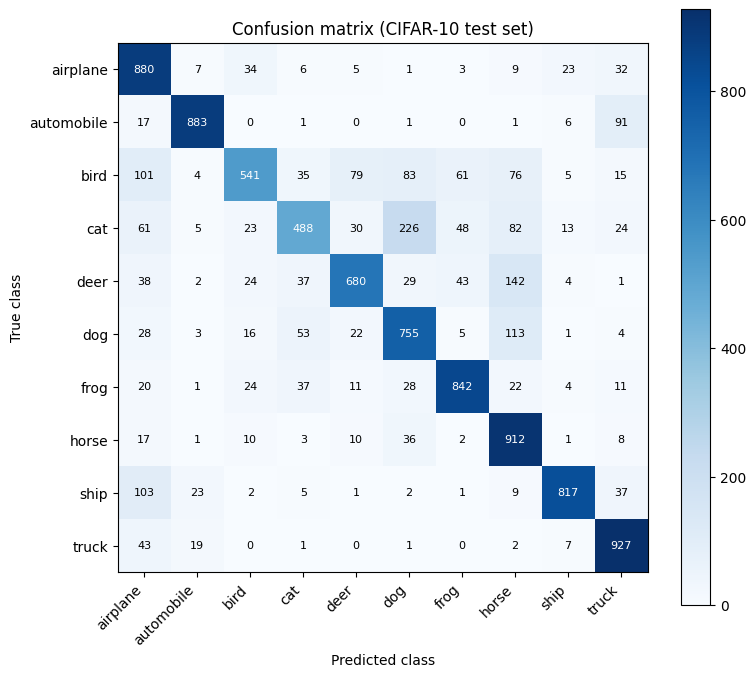

Per-class accuracy:
  airplane   88.0%
  automobile 88.3%
  bird       54.1%
  cat        48.8%
  deer       68.0%
  dog        75.5%
  frog       84.2%
  horse      91.2%
  ship       81.7%
  truck      92.7%

Most frequent confusions (true -> predicted):
  cat        -> dog        226 images
  deer       -> horse      142 images
  dog        -> horse      113 images
  ship       -> airplane   103 images
  bird       -> airplane   101 images


In [9]:
best_label = max(results, key=results.get)
model = adam_model if best_label == 'Adam' else sgd_model
print(f"Final model: {best_label}, test accuracy {results[best_label]:.2%}")

probs = model.predict(test_ds, verbose=0)
pred = probs.argmax(axis=1)

# Confusion matrix (rows = true class, columns = predicted class)
cm = tf.math.confusion_matrix(test_labels, pred, num_classes=10).numpy()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10), class_names, rotation=45, ha='right')
ax.set_yticks(range(10), class_names)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('Confusion matrix (CIFAR-10 test set)')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

print("Per-class accuracy:")
for i, name in enumerate(class_names):
    print(f"  {name:10s} {cm[i, i] / cm[i].sum():.1%}")

off_diag = [(cm[i, j], class_names[i], class_names[j])
            for i in range(10) for j in range(10) if i != j]
print("\nMost frequent confusions (true -> predicted):")
for count, t, p in sorted(off_diag, reverse=True)[:5]:
    print(f"  {t:10s} -> {p:10s} {count} images")

In [10]:
model.save('final_model.keras')
print("Saved final_model.keras")

Saved final_model.keras


## Predicting images of our own

Put photos in the `my_images/` folder (any size; they are resized to 32 × 32). Each one is shown with its predicted class and confidence.

In [ ]:

# Colab only: upload your own images into my_images/ (skipped in local Jupyter)
import os, sys
if 'google.colab' in sys.modules:
    from google.colab import files
    os.makedirs('my_images', exist_ok=True)
    uploaded = files.upload()
    for name, data in uploaded.items():
        with open(os.path.join('my_images', name), 'wb') as f:
            f.write(data)
    print("Uploaded:", ", ".join(uploaded) or "nothing")


sample_deer.png: deer (63.7%)
webots_car.png: automobile (59.9%)


webots_horse.png: horse (100.0%)


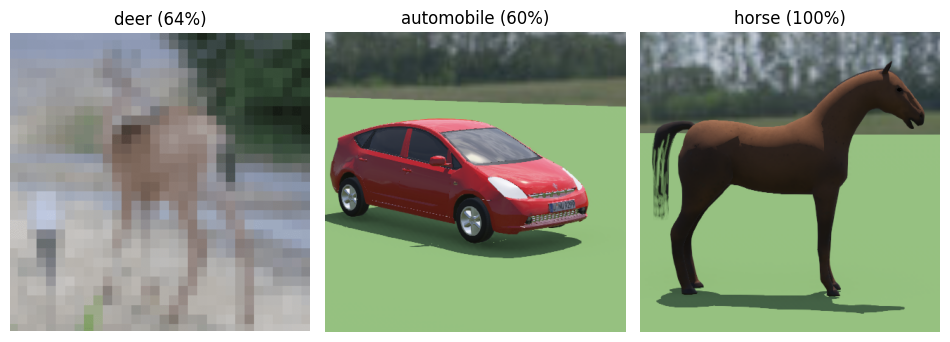

In [11]:
def load_image(filename):
    # Load an image file as a 1x32x32x3 float32 batch in [0, 1]
    img = tf.keras.utils.load_img(filename, target_size=(32, 32))
    img = tf.keras.utils.img_to_array(img) / 255.0
    return img[np.newaxis, ...].astype('float32')

def classify(model, filename):
    p = model.predict(load_image(filename), verbose=0)[0]
    idx = int(np.argmax(p))
    return class_names[idx], float(p[idx])

saved_model = tf.keras.models.load_model('final_model.keras')

IMAGE_DIR = 'my_images'
files = sorted(f for f in os.listdir(IMAGE_DIR)
               if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))) if os.path.isdir(IMAGE_DIR) else []

if not files:
    print(f"No images found in '{IMAGE_DIR}/'. Add some photos and re-run this cell.")
else:
    fig, axes = plt.subplots(1, len(files), figsize=(3.2 * len(files), 3.6), squeeze=False)
    for ax, f in zip(axes[0], files):
        path = os.path.join(IMAGE_DIR, f)
        name, conf = classify(saved_model, path)
        print(f"{f}: {name} ({conf:.1%})")
        ax.imshow(tf.keras.utils.load_img(path))
        ax.set_title(f"{name} ({conf:.0%})")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Optimisation for the robot: TensorFlow Lite and int8 quantisation

The controller must keep the e-puck moving, so inference has to be cheap. The model is converted to TensorFlow Lite in two forms: plain float32, and **full-integer (int8) quantisation**, calibrated on 500 training images. Model size, test accuracy and single-image inference time are then compared.

In [12]:
def representative_data():
    for i in range(500):
        yield [x_train[i:i + 1]]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float = converter.convert()

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8
tflite_int8 = converter.convert()

with open('final_model_int8.tflite', 'wb') as f:
    f.write(tflite_int8)

INFO:tensorflow:Assets written to: C:\Users\Dell\AppData\Local\Temp\tmpqgm3wm5g\assets


INFO:tensorflow:Assets written to: C:\Users\Dell\AppData\Local\Temp\tmpqgm3wm5g\assets


Saved artifact at 'C:\Users\Dell\AppData\Local\Temp\tmpqgm3wm5g'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='keras_tensor_22')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  1267948093280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820262848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820262496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820261792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820263376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820245408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267

INFO:tensorflow:Assets written to: C:\Users\Dell\AppData\Local\Temp\tmptc3zca6k\assets


INFO:tensorflow:Assets written to: C:\Users\Dell\AppData\Local\Temp\tmptc3zca6k\assets


Saved artifact at 'C:\Users\Dell\AppData\Local\Temp\tmptc3zca6k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='keras_tensor_22')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  1267948093280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820262848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820262496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820261792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820263376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820248224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267820245408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267

C:\Users\Dell\AppData\Local\Temp\claude\1ee303c1e4c0ad79\2ef5482c-8b72-44df-988a-ed76c764d308\scratchpad\venv\lib\site-packages\tensorflow\lite\python\convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [13]:
class TFLiteClassifier:
    def __init__(self, model_bytes):
        self.interp = tf.lite.Interpreter(model_content=model_bytes)
        self.interp.allocate_tensors()
        self.inp = self.interp.get_input_details()[0]
        self.out = self.interp.get_output_details()[0]

    def __call__(self, x):  # x: 1x32x32x3 float32 in [0, 1]
        if self.inp['dtype'] == np.uint8:
            scale, zero = self.inp['quantization']
            x = np.clip(np.round(x / scale + zero), 0, 255).astype(np.uint8)
        self.interp.set_tensor(self.inp['index'], x)
        self.interp.invoke()
        return self.interp.get_tensor(self.out['index'])[0]

def tflite_accuracy(clf):
    preds = [np.argmax(clf(test_images[i:i + 1])) for i in range(len(test_images))]
    return np.mean(np.array(preds) == test_labels)

def time_per_image(fn, runs=300):
    x = test_images[:1]
    for _ in range(20):          # warm-up
        fn(x)
    start = time.perf_counter()
    for _ in range(runs):
        fn(x)
    return (time.perf_counter() - start) / runs * 1000  # ms

model.save('tmp_size_check.keras')
keras_size = os.path.getsize('tmp_size_check.keras') / 1024
os.remove('tmp_size_check.keras')

float_clf, int8_clf = TFLiteClassifier(tflite_float), TFLiteClassifier(tflite_int8)

rows = [
    ('Keras model.predict()', keras_size, results[best_label],
     time_per_image(lambda x: model.predict(x, verbose=0), runs=100)),
    ('Keras model(x) call', keras_size, results[best_label],
     time_per_image(lambda x: model(x, training=False))),
    ('TFLite float32', len(tflite_float) / 1024, tflite_accuracy(float_clf),
     time_per_image(float_clf)),
    ('TFLite int8', len(tflite_int8) / 1024, tflite_accuracy(int8_clf),
     time_per_image(int8_clf)),
]

print(f"{'Version':24s}{'Size (KB)':>11s}{'Test acc.':>11s}{'ms / image':>12s}")
for name, size, acc, ms in rows:
    print(f"{name:24s}{size:11.0f}{acc:11.2%}{ms:12.2f}")

C:\Users\Dell\AppData\Local\Temp\claude\1ee303c1e4c0ad79\2ef5482c-8b72-44df-988a-ed76c764d308\scratchpad\venv\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Version                   Size (KB)  Test acc.  ms / image
Keras model.predict()          4693     77.25%      157.38
Keras model(x) call            4693     77.25%       54.58
TFLite float32                 2314     77.25%        1.03
TFLite int8                     592     77.15%        0.97


In [ ]:

# Colab only: download the trained models to your computer (skipped in local Jupyter)
import sys
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download('final_model.keras')
    files.download('final_model_int8.tflite')



## Summary

* **Test accuracy: 77.25 %** on the 10,000 unseen CIFAR-10 test images (SGD with momentum, 20 epochs). This is typical for a small CNN trained from scratch.
* **Per class:** vehicles are easiest (truck 92.7 %, automobile 88.3 %, airplane 88.0 %); cat (48.8 %) and bird (54.1 %) are hardest.
* **Most confused:** cat → dog (226 images), deer → horse (142), dog → horse (113): animals that look alike at 32 × 32 pixels.
* **Own images:** sample deer photo → deer (64 %), red car rendered in Webots → automobile (60 %), horse rendered in Webots → horse (100 %).
* **Optimisation:** TensorFlow Lite answers in about 1 ms per image instead of 55 ms (direct Keras call) or 157 ms (`model.predict`). Int8 quantisation makes the model 8× smaller (592 KB instead of 4.7 MB) and loses only 0.1 points of accuracy.
* **In Webots** the controller found a scaled horse model, drove to it and classified it as horse (99.9 %). A square crop around the object was essential: stretching the wide bounding box to 32 × 32 made the same horse look like a cat.
